In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 50)

In [2]:
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "data").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

RANDOM_STATE = 42
VALID_SIZE = 0.1

RF_PARAMS = {
    "n_estimators": 200,
    "max_depth": 20,
    "min_samples_leaf": 5,
    "max_features": "sqrt",
    "n_jobs": -1,
    "random_state": RANDOM_STATE,
}

XGB_PARAMS = {
    "n_estimators": 1000,
    "learning_rate": 0.1,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "eval_metric": "logloss",
    "early_stopping_rounds": 50,
    "n_jobs": -1,
    "random_state": RANDOM_STATE,
}

SVM_C = 0.1

In [3]:
config = json.loads((MODELS_DIR / "serious_feature_config.json").read_text())
FEATURES = config["feature_columns"]
TARGET = config["target"]

train = pd.read_parquet(PROCESSED_DATA_DIR / "serious_train.parquet")
test = pd.read_parquet(PROCESSED_DATA_DIR / "serious_test.parquet")

fit, valid = train_test_split(
    train,
    test_size=VALID_SIZE,
    random_state=RANDOM_STATE,
    stratify=train[TARGET],
)

X_fit, y_fit = fit[FEATURES], fit[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

for name, y in [("fit", y_fit), ("validation", y_valid), ("test", y_test)]:
    print(f"{name:<10}: {len(y):>7,} reports, serious {y.mean() * 100:.1f}%")

fit       : 278,478 reports, serious 54.6%
validation:  30,942 reports, serious 54.6%
test      :  77,356 reports, serious 54.6%


In [4]:
baseline = DummyClassifier(strategy="most_frequent")

random_forest = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(**RF_PARAMS),
)

xgb_model = XGBClassifier(**XGB_PARAMS)

svm = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    CalibratedClassifierCV(
        LinearSVC(C=SVM_C, random_state=RANDOM_STATE),
        cv=3,
    ),
)

models_to_train = [
    ("Majority class", baseline, {}),
    ("Random Forest", random_forest, {}),
    ("XGBoost", xgb_model, {"eval_set": [(X_valid, y_valid)], "verbose": False}),
    ("SVM", svm, {}),
]

trained = {}
train_seconds = {}

for name, model, fit_options in models_to_train:
    start = time.time()
    model.fit(X_fit, y_fit, **fit_options)

    train_seconds[name] = time.time() - start
    trained[name] = model
    print(f"{name:<15} trained in {train_seconds[name]:.0f} s")

print(f"XGBoost kept {trained['XGBoost'].best_iteration + 1} trees")

Majority class  trained in 0 s


Random Forest   trained in 48 s


XGBoost         trained in 172 s


SVM             trained in 145 s
XGBoost kept 1000 trees


In [5]:
validation_rows = {}

for name, model in trained.items():
    predicted = model.predict(X_valid)
    probability = model.predict_proba(X_valid)[:, 1]

    validation_rows[name] = {
        "accuracy": accuracy_score(y_valid, predicted),
        "precision": precision_score(y_valid, predicted, zero_division=0),
        "recall": recall_score(y_valid, predicted),
        "f1": f1_score(y_valid, predicted),
        "roc_auc": roc_auc_score(y_valid, probability),
    }

validation_results = pd.DataFrame(validation_rows).T
display(validation_results.round(3))

candidates = validation_results.drop(index="Majority class")
BEST_MODEL = candidates["f1"].idxmax()
print(f"\nBest model on validation F1: {BEST_MODEL}")

,accuracy,precision,recall,f1,roc_auc
Majority class,0.546,0.546,1.000,0.707,0.500
Random Forest,0.807,0.788,0.885,0.834,0.888
XGBoost,0.880,0.884,0.899,0.891,0.953
SVM,0.866,0.886,0.867,0.876,0.938



Best model on validation F1: XGBoost


In [6]:
test_rows = {}

for name, model in trained.items():
    predicted = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]

    test_rows[name] = {
        "accuracy": accuracy_score(y_test, predicted),
        "precision": precision_score(y_test, predicted, zero_division=0),
        "recall": recall_score(y_test, predicted),
        "f1": f1_score(y_test, predicted),
        "roc_auc": roc_auc_score(y_test, probability),
    }

test_results = pd.DataFrame(test_rows).T
test_results["train_seconds"] = pd.Series(train_seconds).round(1)
display(test_results.round(3))

,accuracy,precision,recall,f1,roc_auc,train_seconds
Majority class,0.546,0.546,1.000,0.707,0.500,0.0
Random Forest,0.807,0.786,0.887,0.834,0.890,47.9
XGBoost,0.881,0.883,0.902,0.892,0.953,171.9
SVM,0.868,0.887,0.869,0.878,0.939,144.9


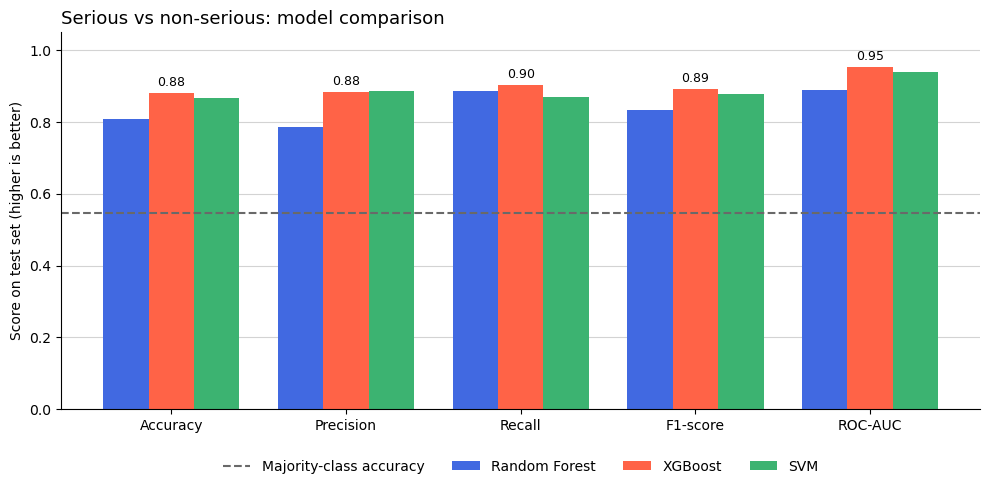

In [7]:
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc"]
metric_labels = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
models_to_plot = ["Random Forest", "XGBoost", "SVM"]

colors = {
    "Random Forest": "royalblue",
    "XGBoost": "tomato",
    "SVM": "mediumseagreen",
}

positions = np.arange(len(metric_names))
width = 0.26

fig, ax = plt.subplots(figsize=(10, 5))

for i, model in enumerate(models_to_plot):
    values = test_results.loc[model, metric_names].astype(float)

    bars = ax.bar(
        positions + (i - 1) * width,
        values,
        width=width,
        color=colors[model],
        label=model,
    )

    if model == BEST_MODEL:
        ax.bar_label(bars, labels=[f"{v:.2f}" for v in values], padding=3, fontsize=9)

ax.axhline(
    test_results.loc["Majority class", "accuracy"],
    color="dimgray",
    linewidth=1.5,
    linestyle="--",
    label="Majority-class accuracy",
)

ax.set_xticks(positions)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score on test set (higher is better)")
ax.set_title("Serious vs non-serious: model comparison", loc="left", fontsize=13)

ax.grid(axis="y", color="lightgrey", linewidth=0.8)
ax.set_axisbelow(True)

for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.1),
    frameon=False,
    ncol=4,
)

plt.tight_layout()
plt.show()

In [8]:
best = trained[BEST_MODEL]
matrix = confusion_matrix(y_test, best.predict(X_test))

display(pd.DataFrame(
    matrix,
    index=["Actually non-serious", "Actually serious"],
    columns=["Predicted non-serious", "Predicted serious"],
))

tn, fp, fn, tp = matrix.ravel()
print(f"{BEST_MODEL}: caught {tp:,} of {tp + fn:,} serious reports, missed {fn:,}, {fp:,} false alarms")

,Predicted non-serious,Predicted serious
Actually non-serious,30055,5039
Actually serious,4152,38110


XGBoost: caught 38,110 of 42,262 serious reports, missed 4,152, 5,039 false alarms


In [9]:
base_accuracy = test_results.loc["Majority class", "accuracy"]

for model in models_to_plot:
    assert test_results.loc[model, "accuracy"] > base_accuracy, f"{model} must beat the majority-class baseline"
    assert test_results.loc[model, "roc_auc"] < 0.99, f"{model}: a near-perfect score would suggest leakage"

assert BEST_MODEL in models_to_plot, "The best model must be one of the three real models"
print("All sanity checks passed.")

All sanity checks passed.


In [10]:
bundle = {
    "model": best,
    "model_name": BEST_MODEL,
    "feature_columns": FEATURES,
    "target": TARGET,
    "threshold": 0.5,
    "test_metrics": test_results.loc[BEST_MODEL, metric_names].astype(float).round(4).to_dict(),
}

joblib.dump(bundle, MODELS_DIR / "serious_best_model.joblib", compress=3)
test_results.round(4).to_csv(MODELS_DIR / "serious_metrics.csv")

for name in ["serious_best_model.joblib", "serious_metrics.csv"]:
    size_mb = (MODELS_DIR / name).stat().st_size / 1024**2
    print(f"Saved models/{name}  ({size_mb:.1f} MB)")

Saved models/serious_best_model.joblib  (0.9 MB)
Saved models/serious_metrics.csv  (0.0 MB)
